# Customer Churn Prediction — Full Analysis & Model Pipeline

This notebook covers:
1. Data loading, cleaning & EDA
2. Encoding (with saved encoders so the Streamlit app stays consistent with training)
3. Train/test split + scaling
4. Model training — Random Forest vs Logistic Regression (comparison)
5. Evaluation — Confusion Matrix, ROC-AUC, Precision-Recall curves
6. Feature Importance
7. SHAP explainability
8. Saving all artifacts needed by `app.py` (the Streamlit dashboard)

> Run all cells top to bottom before running the Streamlit app — the app loads the files this notebook saves.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
print("Libraries loaded.")

Libraries loaded.


## 1. Load & Explore Data

In [3]:
df = pd.read_csv('customer-churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [5]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0


In [6]:
df.drop_duplicates(inplace=True)
print("Shape after dropping duplicates:", df.shape)

Shape after dropping duplicates: (7043, 21)


## 2. Data Cleaning

`TotalCharges` is stored as text with some blank strings (new customers with 0 tenure) — convert to numeric and drop the resulting nulls.

In [7]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Nulls created by conversion:", df["TotalCharges"].isnull().sum())
df.dropna(subset=["TotalCharges"], inplace=True)
print("Shape after cleaning:", df.shape)

Nulls created by conversion: 11
Shape after cleaning: (7032, 21)


In [8]:
# customerID is a unique identifier, not a predictive feature — drop it before modeling
df.drop(columns=["customerID"], inplace=True, errors="ignore")

print("Churn distribution:\n", df["Churn"].value_counts(normalize=True))

Churn distribution:
 Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64


## 3. Encoding

Target (`Churn`) is mapped to 0/1. Every other categorical column is label-encoded, and **each encoder is saved** so the Streamlit app can transform user input the exact same way the model was trained on — this avoids the encoding-mismatch bug from the first version, where hardcoded dictionaries in the app didn't match `LabelEncoder`'s actual (alphabetical) mapping.

In [9]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("Categorical columns to encode:", categorical_cols)

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

df.head()

Categorical columns to encode: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
gender: {'Female': np.int64(0), 'Male': np.int64(1)}
Partner: {'No': np.int64(0), 'Yes': np.int64(1)}
Dependents: {'No': np.int64(0), 'Yes': np.int64(1)}
PhoneService: {'No': np.int64(0), 'Yes': np.int64(1)}
MultipleLines: {'No': np.int64(0), 'No phone service': np.int64(1), 'Yes': np.int64(2)}
InternetService: {'DSL': np.int64(0), 'Fiber optic': np.int64(1), 'No': np.int64(2)}
OnlineSecurity: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
OnlineBackup: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
DeviceProtection: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
TechSupport: {'No': np.int64(0), 'No internet service': np.int64(1), 'Ye

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


## 4. Train/Test Split & Scaling

In [10]:
X = df.drop("Churn", axis=1)
y = df["Churn"]
feature_columns = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Random Forest doesn't need scaling, but Logistic Regression does
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (5625, 19)  Test shape: (1407, 19)


## 5. Model Training — Random Forest vs Logistic Regression

Training both so we can put a real comparison table in front of an interviewer instead of a single unexamined model.

In [11]:
rf_model = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=42
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest trained.")
print(classification_report(y_test, rf_pred))

Random Forest trained.
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.63      0.48      0.54       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.77      0.79      0.78      1407



In [12]:
lr_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)
lr_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression trained.")
print(classification_report(y_test, lr_pred))

Logistic Regression trained.
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



## 6. Model Comparison Table

In [13]:
def evaluate(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

comparison_df = pd.DataFrame([
    evaluate("Random Forest", y_test, rf_pred, rf_proba),
    evaluate("Logistic Regression", y_test, lr_pred, lr_proba),
]).set_index("Model").round(4)

comparison_df

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Random Forest,0.7861,0.6281,0.4786,0.5432,0.8162
Logistic Regression,0.7264,0.4909,0.7941,0.6067,0.8337


In [14]:
# Auto-select the stronger model by ROC-AUC for the app's default prediction tab
best_model_name = comparison_df["ROC-AUC"].idxmax()
best_model = rf_model if best_model_name == "Random Forest" else lr_model
best_uses_scaling = best_model_name == "Logistic Regression"
print(f"Best model by ROC-AUC: {best_model_name}")

Best model by ROC-AUC: Logistic Regression


## 7. Confusion Matrix

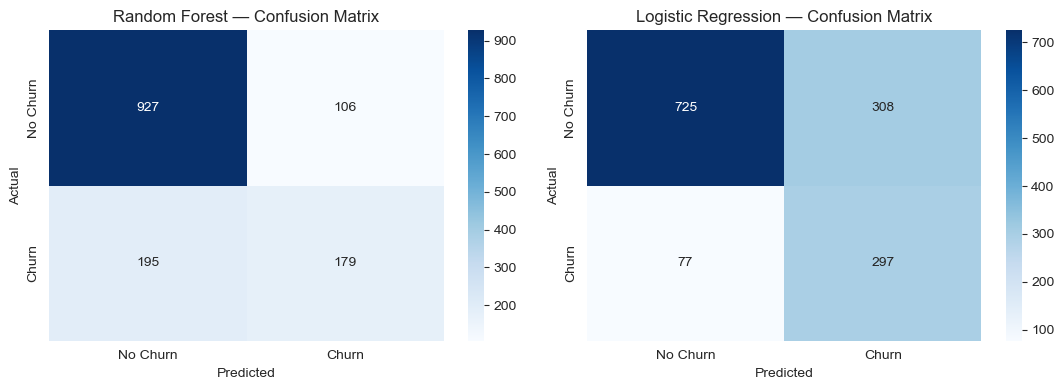

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, preds) in zip(axes, [("Random Forest", rf_pred), ("Logistic Regression", lr_pred)]):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'], ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'{name} — Confusion Matrix')

plt.tight_layout()
plt.savefig("confusion_matrix.png", bbox_inches="tight")
plt.show()

## 8. ROC Curve & Precision-Recall Curve

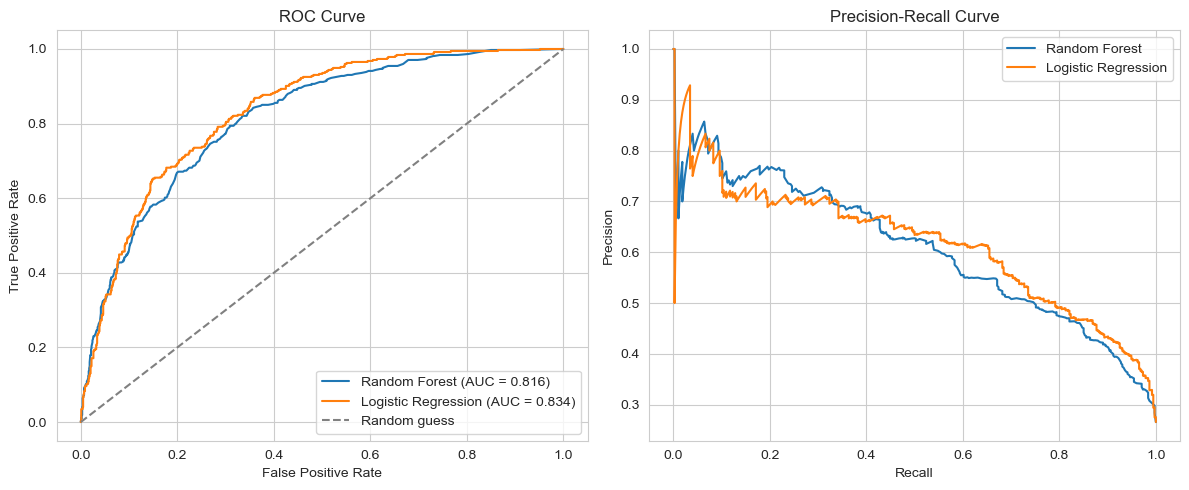

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC Curve
for name, proba in [("Random Forest", rf_proba), ("Logistic Regression", lr_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

# Precision-Recall Curve
for name, proba in [("Random Forest", rf_proba), ("Logistic Regression", lr_proba)]:
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=name)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.savefig("roc_pr_curves.png", bbox_inches="tight")
plt.show()

## 9. Feature Importance (Random Forest)

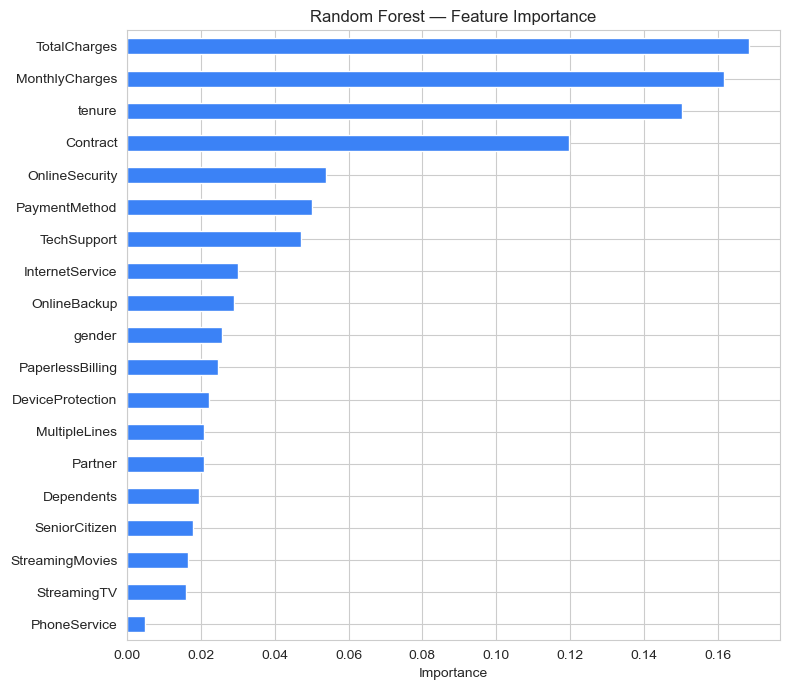

In [17]:
importances = pd.Series(rf_model.feature_importances_, index=feature_columns).sort_values(ascending=True)

plt.figure(figsize=(8, 7))
importances.plot(kind="barh", color="#3B82F6")
plt.title("Random Forest — Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", bbox_inches="tight")
plt.show()

## 10. SHAP Explainability

Feature importance tells you *what* matters on average. SHAP tells you *how* each feature pushed an individual prediction up or down — this is what actually gets discussed in interviews when someone asks "how does your model make decisions?".

In [ ]:
# Uncomment the line below the first time you run this — SHAP isn't in the default kernel
!pip install shap --quiet

import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

# shap_values is a list [class_0, class_1] for classifiers — we want the "churn" (class 1) contributions
shap_vals_churn = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure()
shap.summary_plot(shap_vals_churn, X_test, feature_names=feature_columns, plot_type="bar", show=False)
plt.title("SHAP Feature Impact on Churn Prediction")
plt.tight_layout()
plt.savefig("shap_summary.png", bbox_inches="tight")
plt.show()

## 11. Save All Artifacts for the Streamlit App

Everything below gets loaded by `app.py`. Saving the trained encoders + scaler (not hardcoded dictionaries) is the key fix from the previous version — it guarantees the app encodes user input **exactly** the way the model was trained.

In [ ]:
with open("model.pkl", "wb") as f:
    pickle.dump(best_model, f)

with open("rf_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("lr_model.pkl", "wb") as f:
    pickle.dump(lr_model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("label_encoders.pkl", "wb") as f:
    pickle.dump(label_encoders, f)

with open("feature_columns.pkl", "wb") as f:
    pickle.dump(feature_columns, f)

metadata = {
    "best_model_name": best_model_name,
    "best_uses_scaling": best_uses_scaling,
    "comparison_table": comparison_df,
}
with open("metadata.pkl", "wb") as f:
    pickle.dump(metadata, f)

# Save test-set predictions so the app's "Model Performance" tab doesn't need to retrain anything
test_results = X_test.copy()
test_results["y_true"] = y_test.values
test_results["rf_pred"] = rf_pred
test_results["rf_proba"] = rf_proba
test_results["lr_pred"] = lr_pred
test_results["lr_proba"] = lr_proba
test_results.to_csv("test_results.csv", index=False)

print("All artifacts saved:")
print("  model.pkl, rf_model.pkl, lr_model.pkl, scaler.pkl,")
print("  label_encoders.pkl, feature_columns.pkl, metadata.pkl, test_results.csv")
print("  confusion_matrix.png, roc_pr_curves.png, feature_importance.png, shap_summary.png")
print("\nNow run: streamlit run app.py")